# Crosswhite fire case: daily Outlook at the discovery location

Follow the Crosswhite case featured in the FLARE live demo using the nearest native Outlook pixel. This notebook reads the daily files present in `outlook/data/`; the public sample currently covers **July 10–19, 2026**. It also works with additional days from the catalog when downloaded.

**Incident reference:** NIFC record **575138**, name **0445 CROSSWHITE**, IRWIN ID `1b0219ee-5298-4fef-9927-c2666d9d53fc`. The archived incident record used for the demo gives latitude **44.8033386684882**, longitude **−120.199180937817**, and recorded discovery **2026-07-16 00:51:54 UTC** (**July 15, 5:51:54 p.m. PDT**). Discovery is the event marker, not an inferred ignition time.

The reader finds the nearest original pixel by spherical distance and verifies that its coordinates remain unchanged across the daily files. Locations more than 25 km from the grid are rejected.

The demo's Wheeler County high-Outlook percentages describe the share of eligible county land with index ≥0.70. The charts below show a **single native pixel**, not that county-wide percentage. Source context: the supplied `FLARE-live-demo-2m55s-narrated.mp4` and its archived NIFC incident reference.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'manifest.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'manifest.json').exists(), 'Run from the package root or notebooks folder.'
sys.path.insert(0, str(ROOT / 'examples'))
import outlook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
CASE_NAME = 'Crosswhite'
LATITUDE, LONGITUDE = 44.8033386684882, -120.199180937817
DISCOVERY = pd.Timestamp('2026-07-16T00:51:54Z')

# Use only downloaded files, retaining the full catalog for optional extra days.
catalog = outlook.catalog().sort_values('date')
available = catalog.loc[catalog['file'].map(lambda name: (ROOT / name).is_file())]
assert len(available) > 0, 'Download daily NetCDF files into outlook/data/.'
print(f'{len(available)} daily files: {available.iloc[0].date} to {available.iloc[-1].date}')

with outlook.open_day(available.iloc[0].date) as first:
    row, col, distance = outlook.nearest_pixel(first, LATITUDE, LONGITUDE)
    grid_lat, grid_lon = float(first.lat[row, col]), float(first.lon[row, col])

records = []
for date in available.date:
    with outlook.open_day(date) as ds:
        assert float(ds.lat[row, col]) == grid_lat and float(ds.lon[row, col]) == grid_lon
        records.append(dict(
            issue=pd.Timestamp(ds.attrs['forecast_issue_time']),
            valid_start=pd.Timestamp(ds.attrs['time_coverage_start']),
            valid_end=pd.Timestamp(ds.attrs['time_coverage_end']),
            outlook_index=ds.outlook_index[row, col].item(),
            category=ds.category[row, col].item()))
series = pd.DataFrame(records).sort_values('issue').reset_index(drop=True)
series['issued_before_discovery'] = series.issue < DISCOVERY
series['valid_at_discovery'] = (series.valid_start <= DISCOVERY) & (DISCOVERY < series.valid_end)
series.attrs.update(row=row, col=col, latitude=grid_lat, longitude=grid_lon, distance_km=distance)
prior = series.loc[series.issued_before_discovery]
last_prior = prior.iloc[-1] if len(prior) else None
print('Recorded discovery (UTC):', DISCOVERY)
print('Recorded discovery (PDT):', DISCOVERY.tz_convert('America/Los_Angeles'))
print('Selected native pixel:', series.attrs)
if last_prior is not None:
    print('Last issue before discovery:', last_prior.issue)
    print('Issue-to-discovery interval:', DISCOVERY - last_prior.issue)
series


10 daily files: 2026-07-10 to 2026-07-19


Recorded discovery (UTC): 2026-07-16 00:51:54+00:00
Recorded discovery (PDT): 2026-07-15 17:51:54-07:00
Selected native pixel: {'row': 1310, 'col': 2000, 'latitude': 44.80170822143555, 'longitude': -120.19766998291016, 'distance_km': 0.21711602345983574}
Last issue before discovery: 2026-07-15 03:00:00+00:00
Issue-to-discovery interval: 0 days 21:51:54


,issue,valid_start,valid_end,outlook_index,category,issued_before_discovery,valid_at_discovery
0,2026-07-10 03:00:00+00:00,2026-07-10 12:00:00+00:00,2026-07-11 12:00:00+00:00,0.857592,6,True,False
1,2026-07-11 03:00:00+00:00,2026-07-11 12:00:00+00:00,2026-07-12 12:00:00+00:00,0.698448,3,True,False
2,2026-07-12 03:00:00+00:00,2026-07-12 12:00:00+00:00,2026-07-13 12:00:00+00:00,0.713485,4,True,False
3,2026-07-13 03:00:00+00:00,2026-07-13 12:00:00+00:00,2026-07-14 12:00:00+00:00,0.796816,5,True,False
4,2026-07-14 03:00:00+00:00,2026-07-14 12:00:00+00:00,2026-07-15 12:00:00+00:00,0.799841,5,True,False
5,2026-07-15 03:00:00+00:00,2026-07-15 12:00:00+00:00,2026-07-16 12:00:00+00:00,0.708611,4,True,True
6,2026-07-16 03:00:00+00:00,2026-07-16 12:00:00+00:00,2026-07-17 12:00:00+00:00,0.745520,4,False,False
7,2026-07-17 03:00:00+00:00,2026-07-17 12:00:00+00:00,2026-07-18 12:00:00+00:00,0.673334,3,False,False
8,2026-07-18 03:00:00+00:00,2026-07-18 12:00:00+00:00,2026-07-19 12:00:00+00:00,0.507563,2,False,False
9,2026-07-19 03:00:00+00:00,2026-07-19 12:00:00+00:00,2026-07-20 12:00:00+00:00,0.730470,4,False,False


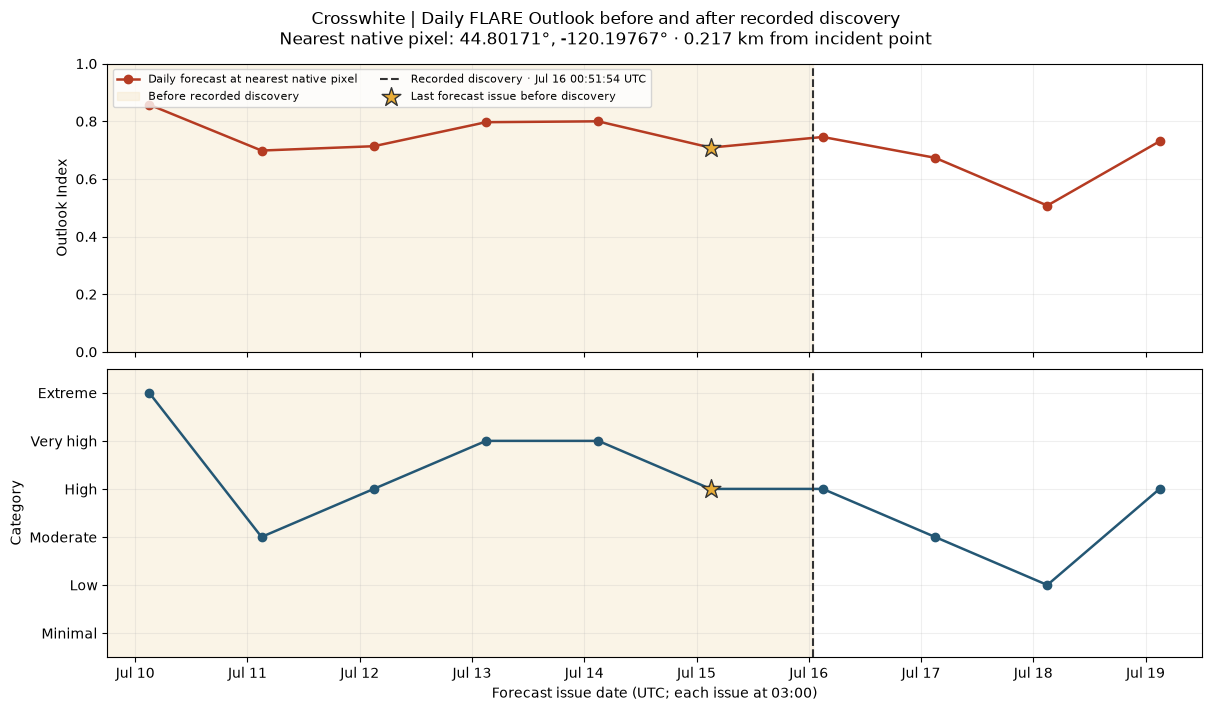

In [3]:
import matplotlib.dates as mdates
from datetime import timezone

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout='constrained')
start = min(series.issue.min(), DISCOVERY) - pd.Timedelta(hours=9)
end = max(series.issue.max(), DISCOVERY) + pd.Timedelta(hours=9)
for ax, key in zip(axes, ['outlook_index', 'category']):
    values = series[key].where(series[key] != 0) if key == 'category' else series[key]
    # Insert missing days as gaps, without interpolating forecast values.
    dates = pd.date_range(series.issue.min(), series.issue.max(), freq='D')
    plotted = pd.Series(values.to_numpy(), index=series.issue).reindex(dates)
    ax.plot(plotted.index, plotted.values, marker='o', linewidth=1.8,
            color='#b53b22' if key == 'outlook_index' else '#245774',
            label='Daily forecast at nearest native pixel')
    ax.axvspan(start, DISCOVERY, color='#f6e7cb', alpha=.45, label='Before recorded discovery')
    ax.axvline(DISCOVERY, color='#333333', linestyle='--', linewidth=1.5,
               label='Recorded discovery · Jul 16 00:51:54 UTC')
    if last_prior is not None and pd.notna(last_prior[key]) and not (key == 'category' and last_prior[key] == 0):
        ax.scatter([last_prior.issue], [last_prior[key]], marker='*', s=200,
                   color='#e9ad37', edgecolors='#333333', zorder=6,
                   label='Last forecast issue before discovery')
    ax.set_ylabel(key.replace('_', ' ').title())
    ax.grid(alpha=.2)
    ax.set_xlim(start, end)
axes[0].set_ylim(0, 1)
axes[0].legend(loc='upper left', fontsize=8, ncol=2)
axes[1].set_ylim(.5, 6.5)
axes[1].set_yticks(range(1, 7), outlook.CATEGORY_LABELS[1:])
axes[1].xaxis.set_major_locator(mdates.DayLocator(tz=timezone.utc))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %d', tz=timezone.utc))
axes[1].set_xlabel('Forecast issue date (UTC; each issue at 03:00)')
fig.suptitle(f'{CASE_NAME} | Daily FLARE Outlook before and after recorded discovery\n'
             f'Nearest native pixel: {grid_lat:.5f}°, {grid_lon:.5f}° · {distance:.3f} km from incident point')
plt.show()


Class 0 is displayed as a gap, not as a low category. The table retains the original 0 codes and includes the valid interval for every available daily forecast. Missing daily files are not interpolated.

The star marks the last issue before recorded discovery. The `valid_at_discovery` column identifies which forecast validity window contains that time. Issue-to-discovery time is a timestamp comparison; the plotted values are daily Outlook values rather than FireScore observations.